# Reliability audit: CS-MON and A0 only

**Run manually with Run All in the existing CS-MON GPU (WSL) kernel, from the project root. This notebook is intentionally unexecuted.**

This audit is restricted to CS-MON and A0. The saved experiment reports **A0 = 98.3108% test accuracy**, the highest recorded result, and **CS-MON/A4 = 91.2162%**. A0 is RGB-only VMamba with an ordinary three-class head and no augmentation. Its weights were not saved: only CS-MON has a persisted checkpoint. This notebook distinguishes **historical evidence**, **original saved-checkpoint measurements** and **fresh independent training runs**. Fresh A0 results are not presented as a reload of the old A0.

Run All trains **CS-MON and A0 only** from the existing cached ImageNet initialization with three seeds under the original full schedule, retaining results in memory. This is a substantial GPU workload (**6 runs**, up to 23 epochs each). If verified physical grouping metadata are supplied, an additional grouped cross-validation experiment runs. Epochs and selection follow the original validation-only protocol; test results do not choose weights or hyperparameters.

All figures/tables are inline. No project file other than this new notebook is created or changed, no downloads or installs run, and no model/CSV/image exports are written. The pinned source uses the already installed CUDA scan extension with PyTorch cross-scan to avoid Triton compilation. Missing scientific evidence is reported as **unverified**, never as a passing check.

## Audit design and evidence boundaries

| Check | Computation and diagram | What is needed for a strong conclusion |
|---|---|---|
| 1 Overfitting | Historical loss/F1; fresh epoch-wise train/validation loss, accuracy, Macro-F1 | Curves for the actual run, with independent validation |
| 2 Physical leakage | Group overlap tables and split diagram | Verified sample, batch and capture-session IDs |
| 3 Duplicates | Recomputed byte/pixel hashes, dHash and pHash, pair galleries | Manual review; perceptual hashes can miss duplicates |
| 4 Class performance | Per-class scores and confusion matrices | Adequate support for all three classes |
| 5 Background shortcut | Verified food removal/crop where supplied; separate central-occlusion probe | Reviewed food extent for genuine background-only input |
| 6 Device/lighting | Sliced metrics, supports, metadata-only baseline | Sufficient class coverage and new-device holdouts |
| 7 Unseen samples | Evaluate optional new sample records | New pieces/batches/days with reliable labels |
| 8 Stability | Three training seeds; physical-group folds when possible | Repeated training plus verified groups |
| 9 Labels | Review provenance and optional dosage records | Preparation/dosage records and class rules |
| 10 Evaluation | Strict load, eval mode, mapping, deterministic inputs, in-memory serialization round trip | Identical probabilities after reconstruction |

No ROI masks, physical IDs or dosage records are currently present in the manifest. You can supply records **inside the configuration cell**, without creating another file. Do not invent IDs or infer physical identity from filename prefixes. Duplicate components are not physical sample IDs.

In [1]:
import sys
sys.dont_write_bytecode=True
import os, io, re, json, ast, math, random, time, copy, gc, hashlib, types, functools
from pathlib import Path
from html.parser import HTMLParser
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.fft import dctn
from sklearn.metrics import (accuracy_score,precision_recall_fscore_support,f1_score,
    mean_absolute_error,cohen_kappa_score,confusion_matrix,classification_report)
from sklearn.model_selection import StratifiedGroupKFold,GroupShuffleSplit
from sklearn.decomposition import PCA
from tqdm.auto import tqdm
from IPython.display import display,Markdown
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset,DataLoader
from torchvision import transforms,models
import kornia.color as colour

os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

AUDIT={
 'seeds':[42,123,2026], 'batch_size':None, 'group_folds':3,
 'near_hash_distance':6, 'duplicate_gallery_pairs':10,
 'probe_examples_per_class':12, 'min_slice_n':15,
 # Add only real verified records here; leave empty if unavailable:
 'physical_metadata':[], # {'image_id':'BIN62','sample_id':'...','preparation_batch_id':'...','capture_session_id':'...'}
 'physical_ids_verified':False,
 'food_boxes':{}, # image_id: [left,top,right,bottom] in EXIF-oriented normalized [0,1] coordinates
 'food_boxes_verified':False, # boxes must enclose ALL food, not merely its central region
 'new_samples':[], # {'relative_path':'...','label':2,'sweet':'Boondhi','device':'...','lighting':'...',
                   #  'sample_id':'...','preparation_batch_id':'...','capture_session_id':'...','capture_date':'YYYY-MM-DD'}
 'new_sample_independence_verified':False,
 'dosage_records':[], # {'image_id':'...','dose':numeric,'unit':'...','reference':'...','label_verified':True}
}
ROOT=Path.cwd().resolve()
assert (ROOT/'02_training_evaluation.ipynb').is_file(),'Use the project root as working directory.'
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type=='cuda','Use the existing WSL CUDA kernel for this full multi-run audit.'
LABELS={'Low':0,'Medium':1,'High':2}; CLASS_NAMES=list(LABELS)
source_nb=json.loads((ROOT/'02_training_evaluation.ipynb').read_text(encoding='utf-8'))
payload=torch.load(ROOT/'outputs'/'best_csmon.pt',map_location='cpu',weights_only=False)
CONFIG=copy.deepcopy(payload['config'])
CONFIG.update(mode='full',save_best_model=False,num_workers=0)
CONFIG['batch_size']=AUDIT['batch_size'] or payload.get('hardware',{}).get('batch_size',2)
BATCH_SIZE=int(CONFIG['batch_size']); WORKERS=0
AMP=bool(CONFIG['use_amp'] and DEVICE.type=='cuda')
CACHE=Path.home()/'.cache'/'csmon'
assert payload['class_mapping']==LABELS
manifest_path=ROOT/'outputs'/'split_manifest.csv'
manifest=pd.read_csv(manifest_path).fillna('').reset_index(drop=True)
assert {'relative_path','image_id','label','split','sweet'}<=set(manifest)
assert manifest.image_id.is_unique and manifest.relative_path.is_unique
assert set(manifest.split)=={'train','validation','test'}
assert manifest.label.isin([0,1,2]).all()
assert manifest.colouring_intensity.map(LABELS).eq(manifest.label).all()
if AUDIT['physical_metadata']:
    extra=pd.DataFrame(AUDIT['physical_metadata'])
    assert extra.image_id.is_unique and set(extra.image_id)<=set(manifest.image_id)
    for col in ['sample_id','preparation_batch_id','capture_session_id']:
        if col in extra:
            values=extra.set_index('image_id')[col]
            existing=manifest[col].astype(str) if col in manifest else pd.Series('',index=manifest.index)
            added=manifest.image_id.map(values).fillna('').astype(str)
            conflict=existing.ne('') & added.ne('') & existing.ne(added)
            assert not conflict.any(),f'Conflicting existing {col}'
            manifest[col]=added.where(added.ne(''),existing)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True})
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True
    torch.use_deterministic_algorithms(True,warn_only=True)
seed_everything(AUDIT['seeds'][0])
STATUS=[]
def status(check,state,evidence):
    STATUS.append({'Check':check,'Status':state,'Evidence':evidence})
print('GPU:',torch.cuda.get_device_name(0),'batch:',BATCH_SIZE)
print('Training plan: CS-MON and A0 only ×',len(AUDIT['seeds']),'seeds; original full schedule.')
display(pd.crosstab(manifest.split,[manifest.sweet,manifest.colouring_intensity]))

GPU: NVIDIA GeForce GTX 1650 Ti batch: 2
Training plan: CS-MON and A0 only × 3 seeds; original full schedule.


sweet               Boondhi             Kesari             Muscat            
colouring_intensity    High  Low Medium   High  Low Medium   High  Low Medium
split                                                                        
test                     34   33     32     33   28     30     32   38     36
train                   147  156    151    149  158    155    149  146    145
validation               35   27     33     34   30     31     35   32     35

## Historical results: identify the highest recorded accuracy

Read the stored tables and training logs from notebook 02 without executing it, retaining only CS-MON and A0 for this audit. Ranking is a descriptive audit of the already reported test results; it must not become a new test-based model-selection step. A4 was an alias of CS-MON in that experiment, so those two rows are not independent runs.

,Model,Accuracy,Macro F1
5,A0,0.983108,0.983179
4,CS-MON (Fine-Tuned VMamba-Tiny),0.912200,0.908900


Highest RECORDED accuracy: A0 98.3108%


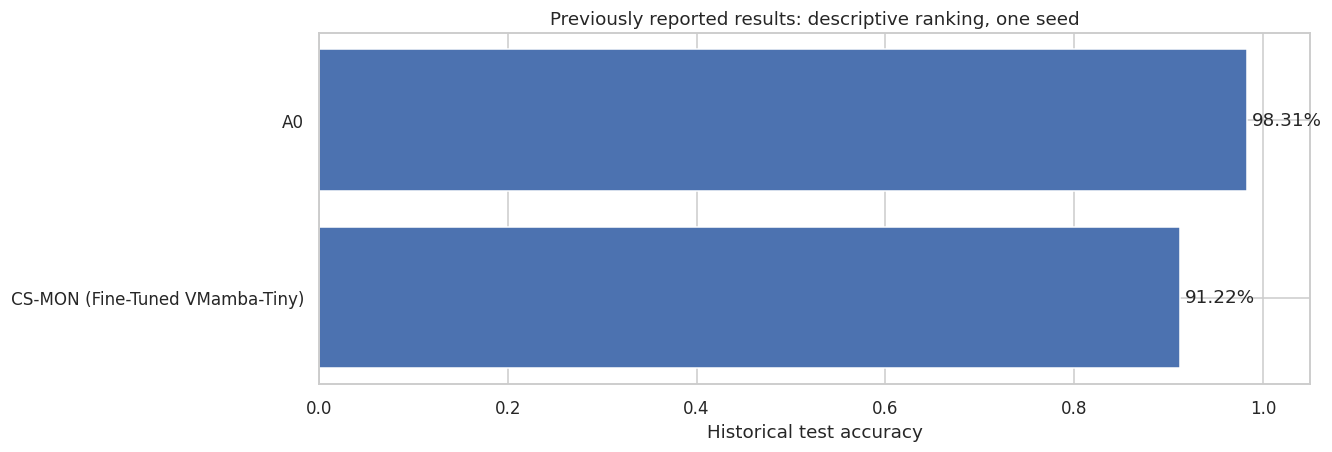

Only the CS-MON checkpoint exists; fresh ablation runs below are replications, not recovered historical weights.


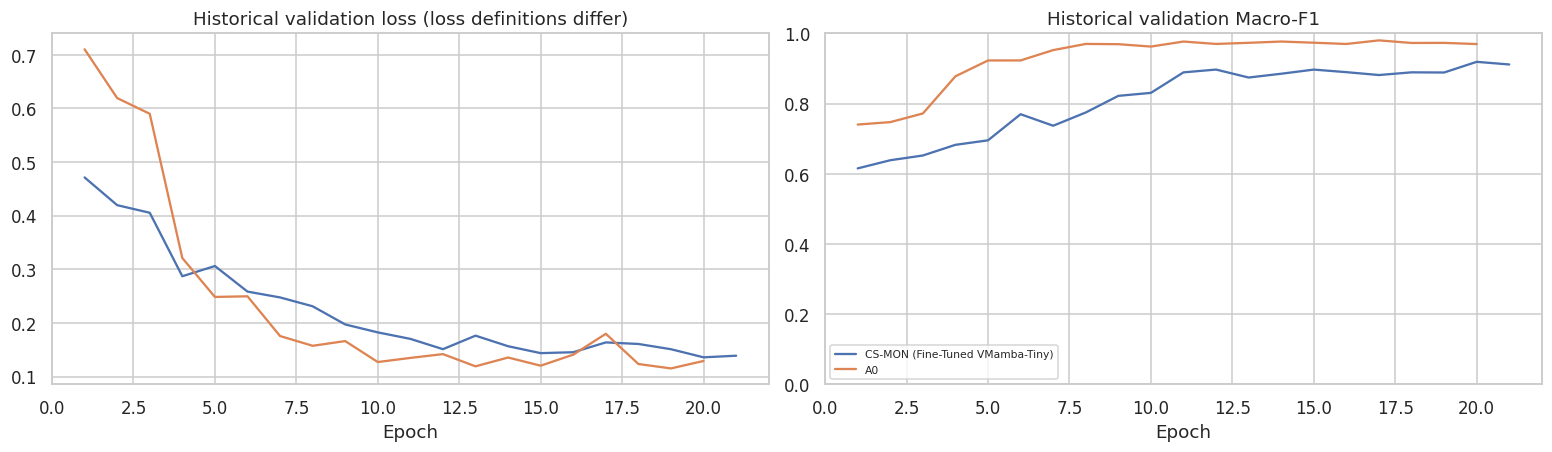

Old logs contain train loss and validation loss/F1, but not epoch-wise train/validation accuracy or train F1.


In [2]:
class TableReader(HTMLParser):
    def __init__(self):
        super().__init__(); self.rows=[]; self.row=None; self.field=None
    def handle_starttag(self,tag,attrs):
        if tag=='tr': self.row=[]
        if tag in ('td','th') and self.row is not None: self.field=[]
    def handle_data(self,text):
        if self.field is not None: self.field.append(text)
    def handle_endtag(self,tag):
        if tag in ('td','th') and self.field is not None:
            self.row.append(''.join(self.field).strip()); self.field=None
        if tag=='tr' and self.row is not None: self.rows.append(self.row); self.row=None
historical=[]
for out in source_nb['cells'][17].get('outputs',[]):
    html=out.get('data',{}).get('text/html',[])
    if html:
        reader=TableReader(); reader.feed(''.join(html))
        for row in reader.rows:
            if len(row)==7:
                try: historical.append({'Model':row[0],'Accuracy':float(row[1]),'Macro F1':float(row[2])})
                except ValueError: pass
for out in source_nb['cells'][27].get('outputs',[]):
    text=''.join(out.get('data',{}).get('text/plain',[]))
    for line in text.splitlines():
        m=re.match(r'^(A[0-4])\s+([0-9.]+)\s+\S+\s+([0-9.]+)',line)
        if m: historical.append({'Model':m[1],'Accuracy':float(m[2]),'Macro F1':float(m[3])})
historical=pd.DataFrame(historical).drop_duplicates('Model')
historical=historical.loc[historical.Model.eq('A0') | historical.Model.str.startswith('CS-MON')].copy()
assert len(historical)>0,'Historical metric table missing from notebook 02 outputs.'
display(historical.sort_values('Accuracy',ascending=False))
highest=historical.loc[historical.Accuracy.idxmax()]
print('Highest RECORDED accuracy:',highest.Model,f'{highest.Accuracy:.4%}')
fig,ax=plt.subplots(figsize=(12,4))
h=historical.sort_values('Accuracy')
ax.barh(h.Model,h.Accuracy); ax.set(xlim=(0,1.05),xlabel='Historical test accuracy',
    title='Previously reported results: descriptive ranking, one seed')
for i,v in enumerate(h.Accuracy): ax.text(v+.005,i,f'{v:.2%}',va='center')
plt.show()
print('Only the CS-MON checkpoint exists; fresh ablation runs below are replications, not recovered historical weights.')
history_rows=[]; current_model=None
for out in source_nb['cells'][15].get('outputs',[]):
    if out.get('output_type')!='stream': continue
    text=''.join(out.get('text',[]))
    for line in text.splitlines():
        m=re.search(r'Training (.+?) : seed (\d+)',line)
        if m: current_model=m[1]
        m=re.search(r'Epoch (\d+) (\w+): train ([\d.]+), val ([\d.]+), macro F1 ([\d.]+)',line)
        if m and current_model:
            history_rows.append(dict(Model=current_model,epoch=int(m[1]),stage=m[2],
                train_loss=float(m[3]),val_loss=float(m[4]),val_f1=float(m[5])))
historical_history=pd.DataFrame(history_rows)
if len(historical_history):
    fig,axes=plt.subplots(1,2,figsize=(14,4))
    for name,part in historical_history.groupby('Model',sort=False):
        if name=='A0' or name.startswith('CS-MON'):
            axes[0].plot(part.epoch,part.val_loss,label=name)
            axes[1].plot(part.epoch,part.val_f1,label=name)
    axes[0].set(title='Historical validation loss (loss definitions differ)',xlabel='Epoch')
    axes[1].set(title='Historical validation Macro-F1',xlabel='Epoch',ylim=(0,1))
    axes[1].legend(fontsize=7); plt.show()
print('Old logs contain train loss and validation loss/F1, but not epoch-wise train/validation accuracy or train F1.')

## Checks 2 and 3: identity, physical leakage and near duplicates

Byte and decoded-pixel checks detect exact copies. dHash and pHash detect some similar compositions even when file bytes differ. Distances are candidate screens, not proof of physical identity. All cross-split candidates are counted; the nearest gallery includes both flagged and nearest unflagged candidates for visual review.

Physical leakage is checked separately. All supplied sample/batch/session links are joined into connected groups, because grouping on only one field can leave another link crossing splits. Missing records mean the physical leakage check cannot pass.

Verify images and recompute hashes:   0%|          | 0/1944 [00:00<?, ?it/s]

,Kind,Count,Splits,Images


All perceptual-hash pairs:   0%|          | 0/1943 [00:00<?, ?it/s]

Candidate pairs: 720 cross-split: 311


,i,j,dHash distance,pHash distance,Cross split
589,1599,1600,5,0,True
175,468,470,5,2,True
199,540,541,7,2,True
245,724,725,5,2,True
322,942,943,6,2,True
379,1094,1133,12,2,True
517,1446,1447,7,2,True
575,1571,1572,13,2,True
585,1594,1596,5,2,True
591,1605,1607,5,2,True


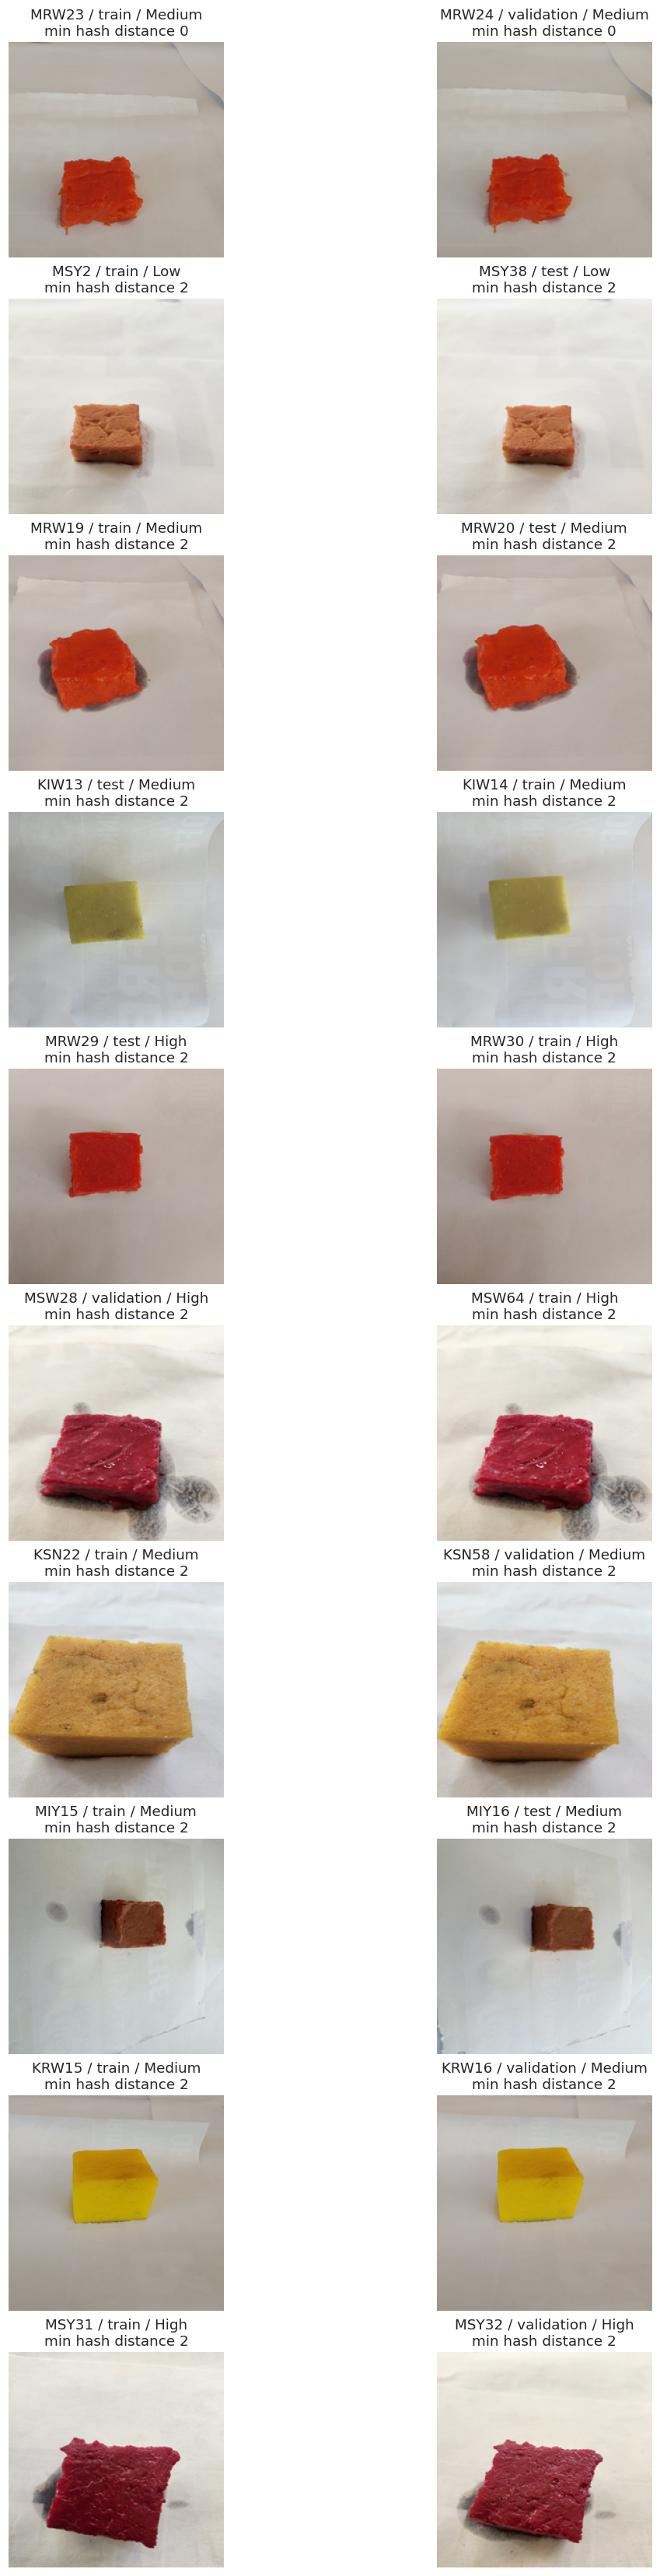

,Field,Coverage,Cross-split IDs
0,audit_component,1.0,0


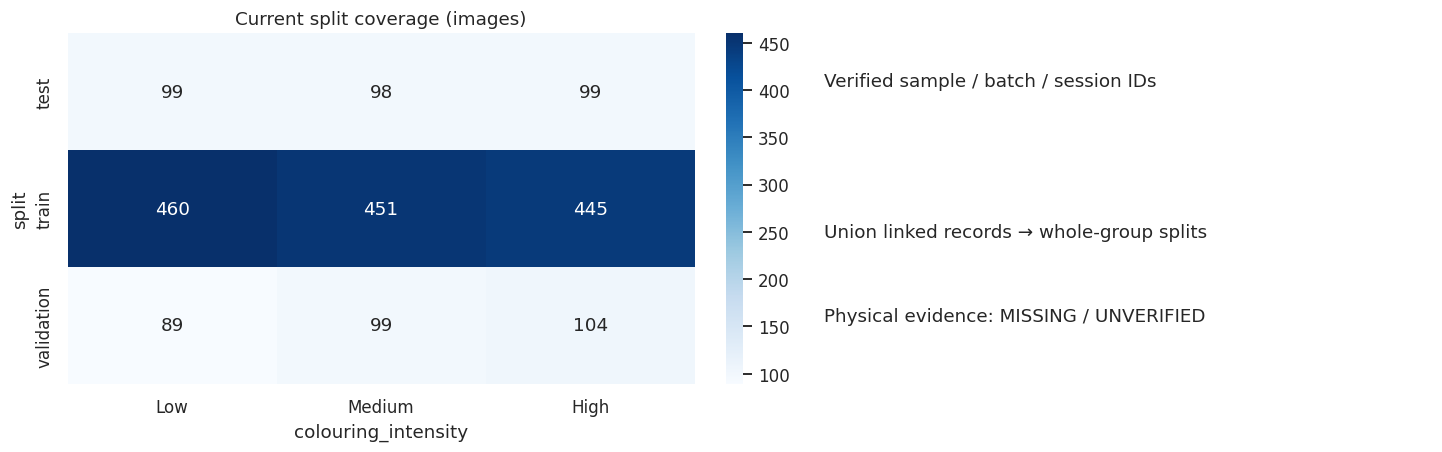

On-disk manifest matches checkpoint: True


In [3]:
def read_image(relative_path,size=None):
    path=(ROOT/str(relative_path)).resolve()
    assert path.is_relative_to(ROOT) and path.is_file(),f'Invalid image path: {path}'
    with Image.open(path) as im: im=ImageOps.exif_transpose(im).convert('RGB')
    return im if size is None else im.resize((size,size),Image.Resampling.LANCZOS)

def image_tensor(relative_path):
    return transforms.functional.to_tensor(read_image(relative_path,CONFIG['image_size']))

identity=[]; dh=[]; ph=[]
for row in tqdm(manifest.itertuples(),total=len(manifest),desc='Verify images and recompute hashes'):
    p=(ROOT/row.relative_path).resolve()
    assert p.is_relative_to(ROOT) and p.is_file()
    byte_hash=hashlib.sha256(p.read_bytes()).hexdigest()
    if hasattr(row,'sha256'): assert byte_hash==row.sha256,f'Image changed: {row.image_id}'
    im=read_image(row.relative_path)
    pixel_hash=hashlib.sha256(str(im.size).encode()+im.tobytes()).hexdigest()
    small=np.asarray(im.convert('L').resize((9,8),Image.Resampling.LANCZOS))
    dh.append((small[:,1:]>small[:,:-1]).reshape(-1))
    gray=np.asarray(im.convert('L').resize((32,32),Image.Resampling.LANCZOS),dtype=float)
    low=dctn(gray,norm='ortho')[:8,:8].reshape(-1)
    bits=low>np.median(low[1:]); bits[0]=False; ph.append(bits)
    identity.append({'image_id':row.image_id,'byte_hash':byte_hash,'pixel_hash':pixel_hash})
identity=pd.DataFrame(identity)
exact=[]
for key in ['byte_hash','pixel_hash']:
    temp=identity.join(manifest[['split']])
    for value,part in temp.groupby(key):
        if len(part)>1: exact.append({'Kind':key,'Count':len(part),'Splits':part.split.nunique(),
            'Images':', '.join(part.image_id)})
exact=pd.DataFrame(exact,columns=['Kind','Count','Splits','Images'])
display(exact)
dh=np.asarray(dh,dtype=bool); ph=np.asarray(ph,dtype=bool)
pairs=[]; nearest=[]; splits=manifest.split.to_numpy()
for i in tqdm(range(len(manifest)-1),desc='All perceptual-hash pairs'):
    dd=np.count_nonzero(dh[i+1:]!=dh[i],axis=1)
    pdist=np.count_nonzero(ph[i+1:]!=ph[i],axis=1)
    dist=np.minimum(dd,pdist)
    js=np.flatnonzero(dist<=AUDIT['near_hash_distance'])+i+1
    for j in js:
        pairs.append((i,int(j),int(dd[j-i-1]),int(pdist[j-i-1]),splits[i]!=splits[j]))
    cross=np.flatnonzero(splits[i+1:]!=splits[i])
    if len(cross):
        k=cross[np.argmin(dist[cross])]
        nearest.append((i,int(i+1+k),int(dd[k]),int(pdist[k]),True))
pairs=pd.DataFrame(pairs,columns=['i','j','dHash distance','pHash distance','Cross split'])
print('Candidate pairs:',len(pairs),'cross-split:',int(pairs['Cross split'].sum()))
if len(pairs): display(pairs.sort_values(['Cross split','pHash distance'],ascending=[False,True]).head(30))
gallery=pd.DataFrame(nearest,columns=pairs.columns).drop_duplicates(['i','j'])
gallery['distance']=gallery[['dHash distance','pHash distance']].min(axis=1)
gallery=gallery.sort_values('distance').head(AUDIT['duplicate_gallery_pairs'])
if len(gallery):
    fig,axes=plt.subplots(len(gallery),2,figsize=(10,3*len(gallery)),squeeze=False)
    for axrow,pair in zip(axes,gallery.itertuples(index=False)):
        i,j=int(pair[0]),int(pair[1])
        for ax,k in zip(axrow,[i,j]):
            r=manifest.iloc[k]; ax.imshow(read_image(r.relative_path,224))
            ax.set_title(f'{r.image_id} / {r.split} / {r.colouring_intensity}\nmin hash distance {pair[-1]}')
            ax.axis('off')
    plt.show()
cross_exact=bool(len(exact) and exact.Splits.gt(1).any())
status('3 Near duplicates','ISSUE' if cross_exact else 'REVIEW',
    f'Exact cross-split copies: {cross_exact}; perceptual cross-split candidates: {int(pairs["Cross split"].sum())}. Gallery requires review; hash negatives do not prove absence.')
group_fields=['sample_id','preparation_batch_id','capture_session_id']
group_overlap=[]
for col in group_fields+['audit_component']:
    if col not in manifest: continue
    valid=manifest[col].astype(str).str.strip().ne('')
    counts=manifest.loc[valid].groupby(col).split.nunique()
    group_overlap.append({'Field':col,'Coverage':float(valid.mean()),'Cross-split IDs':int(counts.gt(1).sum())})
group_overlap=pd.DataFrame(group_overlap)
display(group_overlap)
parent=np.arange(len(manifest))
def find(i):
    while parent[i]!=i:
        parent[i]=parent[parent[i]]; i=parent[i]
    return i
for col in group_fields+['audit_component']:
    if col not in manifest: continue
    valid=manifest[col].astype(str).str.strip().ne('')
    for _,part in manifest.loc[valid].groupby(col):
        ids=part.index.to_numpy()
        for j in ids[1:]: parent[find(int(j))]=find(int(ids[0]))
physical_groups=np.array([find(i) for i in range(len(manifest))])
physical_complete=AUDIT['physical_ids_verified'] and all(
    col in manifest and manifest[col].astype(str).str.strip().ne('').all() for col in group_fields)
physical_cross=any(x['Cross-split IDs']>0 for x in group_overlap.to_dict('records') if x['Field'] in group_fields)
status('2 Physical-sample leakage','ISSUE' if physical_cross else ('SUPPORTED' if physical_complete else 'UNVERIFIED'),
    'Cross-split physical links found.' if physical_cross else 'No supplied links cross; completeness/verification required to exclude hidden links.')
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.heatmap(pd.crosstab(manifest.split,manifest.colouring_intensity).reindex(columns=CLASS_NAMES),
    annot=True,fmt='d',ax=axes[0],cmap='Blues')
axes[0].set_title('Current split coverage (images)')
axes[1].axis('off')
axes[1].text(.03,.85,'Verified sample / batch / session IDs',fontsize=12)
axes[1].annotate('',xy=(.5,.52),xytext=(.5,.76),arrowprops={'arrowstyle':'->'})
axes[1].text(.03,.42,'Union linked records → whole-group splits',fontsize=12)
axes[1].text(.03,.18,'Physical evidence: '+('complete' if physical_complete else 'MISSING / UNVERIFIED'),fontsize=12)
plt.show()
manifest_match=hashlib.sha256(manifest_path.read_bytes()).hexdigest()==payload['manifest_sha256']
print('On-disk manifest matches checkpoint:',manifest_match)
assert manifest_match,'Checkpoint and current split manifest differ; do not silently compare different experiments.'

## Restore models without changing the original experiment

The architecture, metrics, staged optimizer and trainer below are copied from notebook 02. The trainer is extended only to record deterministic, unaugmented **train-evaluation** loss/accuracy/F1 and validation accuracy at each epoch. The original augmented training objective is also retained. Checkpoints are still selected by validation Macro-F1 with validation-loss tie-breaking, not test accuracy. Three-class cross-entropy (A0) and cumulative BCE (ordinal variants) have different scales, so compare loss trends within a model.

Fresh CS-MON and A0 runs both start from the same cached official ImageNet weights. Both designs use the original schedule (head, partial and full fine-tuning), optimizer, learning rates, augmentation policy and early stopping. CS-MON uses gated RGB/HSV/Lab fusion, the ordinal head and training flips; A0 uses RGB only, a three-class head and no flips. The original saved CS-MON is audited separately.

In [4]:
class RGBNormalization(nn.Module):
    def __init__(self):
        super().__init__(); self.register_buffer('mean',torch.tensor([.485,.456,.406]).view(1,3,1,1))
        self.register_buffer('std',torch.tensor([.229,.224,.225]).view(1,3,1,1))
    def forward(self,x): return (x-self.mean)/self.std

def colour_representations(x):
    x=x.float()
    hsv=colour.rgb_to_hsv(x); hsv=torch.cat([hsv[:,:1]/(2*math.pi),hsv[:,1:]],dim=1)
    lab=colour.rgb_to_lab(x)
    lab=torch.cat([lab[:,:1]/50-1,lab[:,1:]/128],dim=1)
    return x*2-1,hsv*2-1,lab

class ColourFusion(nn.Module):
    def __init__(self,channels=12,gated=True):
        super().__init__(); self.gated=gated
        self.projections=nn.ModuleList([nn.Sequential(nn.Conv2d(3,channels,1),nn.GELU()) for _ in range(3)])
        self.gate=nn.Sequential(nn.Linear(3*channels,channels),nn.GELU(),nn.Linear(channels,3))
        self.adapter=nn.Conv2d(channels,3,1)
        nn.init.zeros_(self.adapter.weight); nn.init.zeros_(self.adapter.bias)
        self.last_gates=None
    def forward(self,x):
        assert x.ndim==4 and x.shape[1]==3
        with torch.autocast(device_type=x.device.type,enabled=False): reps=colour_representations(x)
        features=[projection(rep) for projection,rep in zip(self.projections,reps)]
        context=torch.cat([f.mean((2,3)) for f in features],dim=1)
        gates=self.gate(context).softmax(dim=1) if self.gated else context.new_full((x.shape[0],3),1/3)
        fused=sum(f*gates[:,i,None,None,None] for i,f in enumerate(features))
        self.last_gates=gates.detach()
        adapted=x+.1*torch.tanh(self.adapter(fused))
        assert adapted.shape==x.shape
        return adapted

class OrdinalHead(nn.Module):
    def __init__(self,features):
        super().__init__(); self.score=nn.Linear(features,1,bias=False)
        # Start with thresholds [-1, 1]. A gap <= log(4) makes Medium
        # unable to be the uniquely most probable class under argmax.
        # Both thresholds remain learnable; no predictions are forced.
        initial_gap=2.0
        self.first=nn.Parameter(torch.tensor(-initial_gap/2))
        self.raw_gap=nn.Parameter(torch.tensor(math.log(math.expm1(initial_gap-1e-4))))
    def forward(self,x):
        thresholds=torch.stack([self.first,self.first+F.softplus(self.raw_gap)+1e-4])
        return self.score(x)-thresholds

def ordinal_targets(y): return (y[:,None]>torch.arange(2,device=y.device)[None,:]).float()
def ordinal_loss(logits,y): return F.binary_cross_entropy_with_logits(logits,ordinal_targets(y))
def class_probabilities(logits,ordinal=True):
    if not ordinal: return logits.float().softmax(1)
    cumulative=logits.float().sigmoid()
    return torch.stack([1-cumulative[:,0],cumulative[:,0]-cumulative[:,1],cumulative[:,1]],dim=1)

class ResearchModel(nn.Module):
    def __init__(self,backbone,features,fusion=None,ordinal=True,is_vmamba=False):
        super().__init__(); self.backbone=backbone; self.fusion=fusion
        self.normalization=RGBNormalization(); self.ordinal=ordinal; self.is_vmamba=is_vmamba
        self.head=OrdinalHead(features) if ordinal else nn.Linear(features,3)
        self.frozen_backbone=False; self.frozen_modules=[]
    def features(self,x):
        if self.fusion is not None: x=self.fusion(x)
        return self.backbone(self.normalization(x))
    def forward(self,x): return self.head(self.features(x))
    def train(self,mode=True):
        super().train(mode)
        if mode:
            if self.frozen_backbone: self.backbone.eval()
            for module in self.frozen_modules: module.eval()
        return self



def set_stage(model,stage):
    model.frozen_backbone=stage=='head'; model.frozen_modules=[]
    for p in model.backbone.parameters(): p.requires_grad_(stage=='full')
    if stage=='partial':
        b=model.backbone
        if model.is_vmamba: blocks=list(b.layers)[-2:]; model.frozen_modules=[b.patch_embed,*list(b.layers)[:-2]]
        elif hasattr(b,'layer4'): blocks=[b.layer4]; model.frozen_modules=[b.conv1,b.bn1,b.layer1,b.layer2,b.layer3]
        elif hasattr(b,'stage4'): blocks=[b.stage4,b.conv5]; model.frozen_modules=[b.conv1,b.stage2,b.stage3]
        else: blocks=list(b.features)[-3:]; model.frozen_modules=list(b.features)[:-3]
        for block in blocks:
            for p in block.parameters(): p.requires_grad_(True)
        if model.is_vmamba:
            for p in b.classifier.parameters(): p.requires_grad_(True)
    for p in model.head.parameters(): p.requires_grad_(True)
    if model.fusion is not None:
        for p in model.fusion.parameters(): p.requires_grad_(True)
    return model

def optimizer_for(model,stage):
    groups={}
    for name,p in model.named_parameters():
        if not p.requires_grad: continue
        backbone=name.startswith('backbone.')
        lr=(CONFIG['backbone_lr']*(.5 if stage=='full' else 1)) if backbone else CONFIG['head_lr']
        decay=0. if p.ndim<2 or name.endswith('.bias') or getattr(p,'_no_weight_decay',False) else CONFIG['weight_decay']
        key=(backbone,lr,decay)
        groups.setdefault(key,[]).append(p)
    return torch.optim.AdamW([{'params':ps,'lr':lr,'weight_decay':decay,'role':'backbone' if bb else 'new'}
                              for (bb,lr,decay),ps in groups.items()])

def calibration(y,probs,bins=10):
    confidence=probs.max(1); correct=probs.argmax(1)==y; rows=[]; ece=0.
    for i in range(bins):
        mask=(confidence>=i/bins)&((confidence<(i+1)/bins) if i<bins-1 else (confidence<=1))
        n=int(mask.sum())
        if n:
            acc=float(correct[mask].mean()); conf=float(confidence[mask].mean())
            ece+=n/len(y)*abs(acc-conf); rows.append((conf,acc,n))
    return float(ece),pd.DataFrame(rows,columns=['confidence','accuracy','count'])

def metrics(y,probs):
    pred=probs.argmax(1)
    p,r,f,_=precision_recall_fscore_support(y,pred,labels=[0,1,2],average='macro',zero_division=0)
    qwk=cohen_kappa_score(y,pred,labels=[0,1,2],weights='quadratic') if len(np.unique(np.r_[y,pred]))>1 else float('nan')
    return {'Accuracy':accuracy_score(y,pred),'Macro precision':p,'Macro recall':r,'Macro F1':f,
            'Weighted F1':f1_score(y,pred,labels=[0,1,2],average='weighted',zero_division=0),
            'Ordinal MAE':mean_absolute_error(y,pred),'QWK':qwk,'ECE':calibration(y,probs)[0]}

def loss_for(model,logits,y): return ordinal_loss(logits,y) if model.ordinal else F.cross_entropy(logits,y)
def autocast(): return torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=AMP)
def cpu_state(model): return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}

@torch.no_grad()
def predict(model,loader,collect_features=False):
    model.eval(); ys=[]; ps=[]; indices=[]; gates=[]; features=[]; total_loss=0
    for x,y,idx in loader:
        x=x.to(DEVICE,non_blocking=True); y=y.to(DEVICE,non_blocking=True)
        with autocast():
            f=model.features(x); logits=model.head(f); loss=loss_for(model,logits,y)
        prob=class_probabilities(logits,model.ordinal)
        assert prob.shape==(len(y),3) and torch.isfinite(prob).all()
        assert (prob>=-1e-6).all() and torch.allclose(prob.sum(1),torch.ones(len(y),device=DEVICE),atol=1e-5)
        ys.append(y.cpu().numpy()); ps.append(prob.cpu().numpy()); indices.append(idx.numpy())
        total_loss+=loss.item()*len(y)
        if collect_features: features.append(f.float().cpu().numpy())
        if model.fusion is not None: gates.append(model.fusion.last_gates.float().cpu().numpy())
    result={'y':np.concatenate(ys),'probs':np.concatenate(ps),'indices':np.concatenate(indices),'loss':total_loss/len(loader.dataset)}
    if gates: result['gates']=np.concatenate(gates)
    if features: result['features']=np.concatenate(features)
    result['metrics']=metrics(result['y'],result['probs'])
    return result



def train_model(model,loaders):
    model.to(DEVICE)
    scaler=torch.cuda.amp.GradScaler(enabled=AMP)
    prefix=CONFIG['mode']; schedule=[('head',CONFIG[prefix+'_head_epochs']),('partial',CONFIG[prefix+'_finetune_epochs'])]
    if prefix=='full' and CONFIG['full_unfreeze_epochs']>0: schedule.append(('full',CONFIG['full_unfreeze_epochs']))
    assert schedule[1][1]>0
    history=[]; best_state=None; best_key=(-float('inf'),-float('inf')); selected={}; epoch_number=0
    start=time.perf_counter(); backbone_updated=False
    for stage,epochs in schedule:
        if epochs<=0: continue
        set_stage(model,stage); optimizer=optimizer_for(model,stage)
        scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=epochs)
        stage_best=(-float('inf'),-float('inf')); stale=0
        for _ in range(epochs):
            epoch_number+=1; model.train(); optimizer.zero_grad(set_to_none=True); total=0.; seen=0
            lr_roles={role:max([g['lr'] for g in optimizer.param_groups if g['role']==role],default=0.) for role in ['backbone','new']}
            bar=tqdm(loaders['train'],desc=f'{stage} : epoch {epoch_number}',leave=False)
            for batch,(x,y,_) in enumerate(bar):
                x=x.to(DEVICE,non_blocking=True); y=y.to(DEVICE,non_blocking=True)
                accumulation=CONFIG['accumulation_steps']
                window_start=(batch//accumulation)*accumulation
                # Denominator counts samples in this accumulation window, including the last small batch.
                first_sample=window_start*BATCH_SIZE
                window_samples=min(accumulation*BATCH_SIZE,len(loaders['train'].dataset)-first_sample)
                with autocast(): logits=model(x); loss=loss_for(model,logits,y)
                assert torch.isfinite(loss), 'Nonfinite training loss.'
                scaler.scale(loss*len(y)/window_samples).backward()
                if (batch+1)%accumulation==0 or batch+1==len(loaders['train']):
                    scaler.unscale_(optimizer)
                    nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad],CONFIG['gradient_clip'])
                    probe=None
                    if stage!='head' and not backbone_updated:
                        probe=next(p for p in model.backbone.parameters() if p.requires_grad and p.grad is not None and p.grad.abs().sum()>0)
                        before=probe.detach().clone()
                    scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
                    if probe is not None: backbone_updated=not torch.equal(before,probe.detach())
                total+=float(loss.detach())*len(y); seen+=len(y); bar.set_postfix(loss=total/seen)
            training_eval=predict(model,loaders['train_eval'])
            validation=predict(model,loaders['validation']); score=validation['metrics']['Macro F1']
            validation_pred=validation['probs'].argmax(1)
            medium_mask=validation['y']==LABELS['Medium']
            medium_count=int((validation_pred==LABELS['Medium']).sum())
            medium_recall=float((validation_pred[medium_mask]==LABELS['Medium']).mean()) if medium_mask.any() else float('nan')
            ordinal_gap=float(F.softplus(model.head.raw_gap.detach()).cpu())+1e-4 if model.ordinal else float('nan')
            if model.ordinal and ordinal_gap<=math.log(4):
                warnings_message='Ordinal threshold gap <= log(4): Medium cannot be uniquely most probable.'
                print('WARNING:',warnings_message)
            key=(score,-validation['loss'])
            history.append(dict(epoch=epoch_number,stage=stage,train_loss=total/seen,val_loss=validation['loss'],
                                train_eval_loss=training_eval['loss'],train_accuracy=training_eval['metrics']['Accuracy'],
                                train_f1=training_eval['metrics']['Macro F1'],val_accuracy=validation['metrics']['Accuracy'],
                                val_f1=score,backbone_lr=lr_roles['backbone'],new_lr=lr_roles['new'],
                                ordinal_gap=ordinal_gap,val_medium_predictions=medium_count,val_medium_recall=medium_recall))
            if stage!='head' and backbone_updated and key>best_key:
                best_key=key; best_state=cpu_state(model); selected={'epoch':epoch_number,'stage':stage,
                    'validation_macro_f1':score,'validation_loss':validation['loss'],
                    'ordinal_gap':ordinal_gap,'validation_medium_predictions':medium_count,'validation_medium_recall':medium_recall}
            if key>stage_best: stage_best=key; stale=0
            else: stale+=1
            scheduler.step()
            print(f"Epoch {epoch_number:02d} {stage}: train {total/seen:.4f}, val {validation['loss']:.4f}, macro F1 {score:.4f}; gap {ordinal_gap:.4f}, validation Medium predictions {medium_count}, Medium recall {medium_recall:.4f}")
            if CONFIG['use_early_stopping'] and stale>=CONFIG['early_stopping_patience']: break
    assert backbone_updated and best_state is not None, 'No verified backbone update; cannot save a frozen feature extractor as fine-tuned.'
    model.load_state_dict(best_state,strict=True)
    return {'state':best_state,'history':pd.DataFrame(history),'selected':selected,
            'training_seconds':time.perf_counter()-start,'parameters':sum(p.numel() for p in model.parameters()),
            'backbone_updated':backbone_updated}

In [5]:
VMAMBA_KWARGS=copy.deepcopy(payload['architecture']['vmamba_kwargs'])
provenance=payload['vmamba_provenance']
source_path=CACHE/f"vmamba-{provenance['commit']}.py"
assert source_path.is_file(),'Use the existing WSL kernel with its populated CS-MON cache.'
source_bytes=source_path.read_bytes()
assert hashlib.sha256(source_bytes).hexdigest()==provenance['source_sha256']
VMAMBA_MODULE=types.ModuleType('audit_vmamba')
VMAMBA_MODULE.__file__=str(source_path)
sys.modules[VMAMBA_MODULE.__name__]=VMAMBA_MODULE
exec(compile(source_bytes,str(source_path),'exec'),VMAMBA_MODULE.__dict__)
assert getattr(VMAMBA_MODULE,'WITH_SELECTIVESCAN_MAMBA',False),'The existing prebuilt CUDA selective-scan extension is required.'
initial_path=CACHE/'vssm1_tiny_0230s_ckpt_epoch_264.pth'
assert initial_path.is_file(),'Cached official initialization is missing; no download will be attempted.'
assert hashlib.sha256(initial_path.read_bytes()).hexdigest()==provenance['checkpoint_sha256']
initial_payload=torch.load(initial_path,map_location='cpu',weights_only=False)
assert 'model' in initial_payload

SPECS={
 'A0':dict(fusion='rgb',ordinal=False,augment=False),
 'CS-MON':dict(fusion='gated',ordinal=True,augment=True),
}
display(pd.DataFrame(SPECS).T)
def make_model(spec,pretrained=False):
    backbone=VMAMBA_MODULE.VSSM(**VMAMBA_KWARGS)
    if pretrained: backbone.load_state_dict(initial_payload['model'],strict=True)
    backbone.classifier.head=nn.Identity()
    fusion=None if spec['fusion']=='rgb' else ColourFusion(12,gated=spec['fusion']=='gated')
    model=ResearchModel(backbone,768,fusion,spec['ordinal'],is_vmamba=True)
    for module in backbone.modules():
        if isinstance(module,VMAMBA_MODULE.SS2D):
            module.forward_core=functools.partial(module.forward_corev2,
                force_fp32=False,no_einsum=True,selective_scan_backend='mamba',scan_force_torch=True)
    return model

class AuditDataset(Dataset):
    def __init__(self,frame,augment=False):
        self.frame=frame.reset_index(drop=True); self.augment=augment
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        r=self.frame.iloc[i]
        im=read_image(r.relative_path,CONFIG['image_size'])
        if self.augment:
            if torch.rand(())<.5: im=ImageOps.mirror(im)
            if torch.rand(())<.5: im=ImageOps.flip(im)
        return transforms.functional.to_tensor(im),torch.tensor(int(r.label),dtype=torch.long),i
def loader(frame,augment=False,shuffle=False,seed=42):
    return DataLoader(AuditDataset(frame,augment),batch_size=BATCH_SIZE,shuffle=shuffle,
        num_workers=0,pin_memory=True,generator=torch.Generator().manual_seed(seed))
def split_loaders(frame,seed,augment):
    return {s:loader(frame[frame.split==s],augment and s=='train',s=='train',seed)
            for s in ['train','validation','test']} | {
            'train_eval':loader(frame[frame.split=='train'],False,False,seed)}
test_frame=manifest.loc[manifest.split.eq('test')].reset_index(drop=True)
val_frame=manifest.loc[manifest.split.eq('validation')].reset_index(drop=True)
def model_probs(model,batch):
    model.eval()
    with torch.no_grad():
        p=class_probabilities(model(batch.to(DEVICE)),model.ordinal)
    return p.detach().cpu().numpy()

# Scientific checks use unaugmented deterministic preprocessing.
probe=image_tensor(val_frame.iloc[0].relative_path)
torch.testing.assert_close(probe,image_tensor(val_frame.iloc[0].relative_path),rtol=0,atol=0)
saved_spec={**payload['architecture']['spec'],'augment':payload['architecture']['spec']['augment']}
original_model=make_model(saved_spec).to(DEVICE)
original_model.load_state_dict(payload['state_dict'],strict=True)
original_model.eval()
with torch.no_grad():
    original_probe=original_model(probe[None].to(DEVICE))
assert original_probe.shape==(1,2)
print('Saved CS-MON: strict loading, class mapping and deterministic input checks passed.')

,fusion,ordinal,augment
A0,rgb,False,False
CS-MON,gated,True,True


Saved CS-MON: strict loading, class mapping and deterministic input checks passed.


## Checks 4, 5, 6, 7 and 10: reusable audit measurements

**Background test:** verified food boxes must enclose all food. Pixels inside a verified box are replaced by neutral grey for background-only inference; food-only and tight-crop views are also compared. Remaining background can still contain shadows or reflections. Distribution shifts caused by masking complicate interpretation. When verified boxes are absent, a separate **central-occlusion probe** is run automatically; it is NOT called background-only and cannot exclude or confirm background shortcuts.

**Bias:** metrics include sample counts and class coverage for device, lighting and their intersection, plus a training-fitted metadata-only majority baseline. Existing-device slices do not establish unseen-device generalization.

**Unseen samples:** optional new records need new pieces/batches/days and trustworthy labels. Without those records the check remains unverified.

**Reload:** state and architecture round-trip through BytesIO, so no checkpoint file is created. Compare probabilities on the same deterministic validation examples, check eval mode and class-probability normalization. A fresh A0 round-trip verifies the fresh A0, not the missing historical A0.

In [6]:
def round_trip(model,spec):
    inputs=torch.stack([image_tensor(p) for p in val_frame.relative_path.head(3)])
    before=model_probs(model,inputs)
    buffer=io.BytesIO()
    torch.save({'state_dict':cpu_state(model),'spec':spec,'class_mapping':LABELS},buffer)
    buffer.seek(0)
    restored_payload=torch.load(buffer,map_location='cpu',weights_only=False)
    assert restored_payload['class_mapping']==LABELS
    restored=make_model(restored_payload['spec']).to(DEVICE)
    restored.load_state_dict(restored_payload['state_dict'],strict=True); restored.eval()
    after=model_probs(restored,inputs)
    np.testing.assert_allclose(before,after,rtol=1e-5,atol=1e-6)
    np.testing.assert_allclose(after.sum(1),1,atol=1e-5)
    assert (after>=0).all() and all(not m.training for m in restored.modules())
    delta=float(np.abs(before-after).max())
    del restored,restored_payload,buffer; gc.collect(); torch.cuda.empty_cache()
    return delta

def slice_scores(frame,y,p):
    rows=[]
    work=frame.copy()
    if {'device','lighting'}<=set(work):
        work['device × lighting']=work.device.astype(str)+' × '+work.lighting.astype(str)
    for col in ['sweet','device','lighting','device × lighting']:
        if col not in work: continue
        for value,part in work.groupby(col):
            if not str(value).strip(): continue
            idx=part.index.to_numpy()
            score=metrics(y[idx],p[idx])
            rows.append({'Slice':col,'Value':value,'N':len(idx),'Classes':len(np.unique(y[idx])),
                'Accuracy':score['Accuracy'],'Macro F1':score['Macro F1'],
                'Evidence':'limited' if len(idx)<AUDIT['min_slice_n'] or len(np.unique(y[idx]))<3 else 'descriptive'})
    return pd.DataFrame(rows)

def perturbations(model):
    verified=AUDIT['food_boxes_verified'] and bool(AUDIT['food_boxes'])
    if verified:
        frame=test_frame[test_frame.image_id.isin(AUDIT['food_boxes'])].copy().reset_index(drop=True)
        name='Reviewed background-only'
    else:
        frame=test_frame.groupby('label',group_keys=False).head(AUDIT['probe_examples_per_class']).reset_index(drop=True)
        name='Central occlusion PROXY'
    if not len(frame): return {'verified':False,'table':pd.DataFrame(),'examples':[]}
    kept_name='Food region only' if verified else 'Central region retained PROXY'
    crop_name='Food region crop' if verified else 'Central crop PROXY'
    allp={k:[] for k in ['Full RGB',name,kept_name,crop_name]}
    examples=[]
    for r in frame.itertuples():
        t=image_tensor(r.relative_path)
        if verified:
            box=np.asarray(AUDIT['food_boxes'][r.image_id],dtype=float)
            assert box.shape==(4,) and (box>=0).all() and (box<=1).all()
            assert box[2]>box[0] and box[3]>box[1]
        else: box=np.array([.2,.2,.8,.8])
        size=t.shape[-1]; x0,y0,x1,y1=np.rint(box*size).astype(int)
        x0,y0=max(0,x0),max(0,y0); x1,y1=min(size,x1),min(size,y1)
        assert x1>x0 and y1>y0
        removed=t.clone(); removed[:,y0:y1,x0:x1]=.5
        retained=torch.full_like(t,.5); retained[:,y0:y1,x0:x1]=t[:,y0:y1,x0:x1]
        crop=F.interpolate(t[None,:,y0:y1,x0:x1],size=(size,size),mode='bilinear',align_corners=False)[0]
        variants=torch.stack([t,removed,retained,crop])
        p=model_probs(model,variants)
        for key,prob in zip(allp,p): allp[key].append(prob)
        if len(examples)<3:
            examples.append({'image_id':r.image_id,'label':int(r.label),'images':variants.numpy(),'probs':p})
    y=frame.label.to_numpy(dtype=int); full=np.array(allp['Full RGB'])
    rows=[]
    for key,values in allp.items():
        p=np.array(values)
        rows.append({'Input':key,'N':len(y),**metrics(y,p),
            'Agreement with full':float((p.argmax(1)==full.argmax(1)).mean()),
            'Mean confidence':float(p.max(1).mean())})
    return {'verified':verified,'table':pd.DataFrame(rows),'examples':examples,
            'names':list(allp),'frame':frame}

def unseen_evaluation(model):
    if not AUDIT['new_samples']: return None
    frame=pd.DataFrame(AUDIT['new_samples']).reset_index(drop=True)
    assert {'relative_path','label','sample_id','preparation_batch_id','capture_session_id','capture_date'}<=set(frame)
    assert frame.label.isin([0,1,2]).all() and frame.relative_path.is_unique
    assert not frame.relative_path.isin(manifest.relative_path).any()
    for col in ['sample_id','preparation_batch_id','capture_session_id','capture_date']:
        assert frame[col].astype(str).str.strip().ne('').all(),f'New records missing {col}'
        if col in manifest:
            old=set(manifest[col].astype(str))-set([''])
            assert not set(frame[col].astype(str)) & old,f'New records overlap old {col}'
    hashes=[]
    for r in frame.itertuples():
        im=read_image(r.relative_path)
        hashes.append(hashlib.sha256(str(im.size).encode()+im.tobytes()).hexdigest())
    assert not set(hashes)&set(identity.pixel_hash),'New data contain existing decoded images.'
    result=predict(model,loader(frame))
    return {'frame':frame,'metrics':result['metrics'],'verified':bool(
        physical_complete and AUDIT['new_sample_independence_verified'])}

def audit_one(model,name,seed,spec,history=None,deep=True):
    model.eval()
    result=predict(model,loader(test_frame))
    np.testing.assert_array_equal(result['indices'],np.arange(len(test_frame)))
    result.update(name=name,seed=seed,history=history,spec=copy.deepcopy(spec))
    result['slices']=slice_scores(test_frame,result['y'],result['probs'])
    result['reload_max_difference']=round_trip(model,spec)
    if deep:
        result['background']=perturbations(model)
        result['unseen']=unseen_evaluation(model)
    return result

AUDITS={}
AUDITS[('Saved CS-MON',int(payload['seed']))]=audit_one(
    original_model,'Saved CS-MON',int(payload['seed']),saved_spec,deep=True)
saved_report=AUDITS[('Saved CS-MON',int(payload['seed']))]
display(pd.Series(saved_report['metrics'],name='Original saved CS-MON: recomputed test metrics'))
historical_csmon=historical[historical.Model.str.startswith('CS-MON')]
if len(historical_csmon):
    previous=float(historical_csmon.iloc[0].Accuracy)
    print('Recomputed minus historical rounded accuracy:',saved_report['metrics']['Accuracy']-previous)
    print('Precision/backend changes may produce small differences; a material discrepancy requires review.')
del original_model; gc.collect(); torch.cuda.empty_cache()
status('10 Evaluation correctness','SUPPORTED',
    'Saved CS-MON strict load, eval mode, mapping, deterministic preprocessing and in-memory save/reload comparison passed; original A0 weights unavailable.')
print('Original saved CS-MON audit complete; ablation training is next.')

Accuracy           0.912162
Macro precision    0.922317
Macro recall       0.911599
Macro F1           0.908944
Weighted F1        0.909147
Ordinal MAE        0.087838
QWK                0.938095
ECE                0.063780
Name: Original saved CS-MON: recomputed test metrics, dtype: float64

Recomputed minus historical rounded accuracy: -3.783783783783967e-05
Precision/backend changes may produce small differences; a material discrepancy requires review.
Original saved CS-MON audit complete; ablation training is next.


## Fresh CS-MON and A0 training and repeatability

Only **CS-MON and A0** are trained in this notebook: two designs × three seeds = **6 fresh runs**. The original saved CS-MON checkpoint is additionally evaluated without retraining it.

A0's original weights were not saved. Fresh A0 runs start from the cached official ImageNet initialization. Fresh CS-MON runs provide comparable multi-seed stability and complete epoch-wise accuracy/F1 histories; they are separate from the original saved CS-MON. All runs use the original schedule and validation-only selection.

Only one model's training state is retained at a time. Predictions, histories and audit summaries remain in notebook memory. No weights are written to disk. Keep the kernel alive until all diagrams finish, then save this notebook to retain its outputs.

In [7]:
FRESH_RUN_ROWS=[]
for seed in AUDIT['seeds']:
    for name,spec in SPECS.items():
        CONFIG['seed']=int(seed); seed_everything(int(seed))
        print(f'\nFresh replication: {name}, seed {seed}; this is not the historical checkpoint.')
        loaders=split_loaders(manifest,int(seed),spec['augment'])
        model=make_model(spec,pretrained=True).to(DEVICE)
        run=train_model(model,loaders)
        model.load_state_dict(run['state'],strict=True); model.eval()
        # round_trip constructs a model and consumes RNG, but every new run is reseeded explicitly.
        report=audit_one(model,name,int(seed),spec,run['history'],
            deep=int(seed)==int(AUDIT['seeds'][0]))
        report['selection']=run['selected']
        AUDITS[(name,int(seed))]=report
        FRESH_RUN_ROWS.append({'Model':name,'Seed':seed,**report['metrics'],
            'Selected epoch':run['selected']['epoch'],
            'Validation Macro F1':run['selected']['validation_macro_f1'],
            'Reload max difference':report['reload_max_difference']})
        del model,run,loaders; gc.collect(); torch.cuda.empty_cache()
fresh_results=pd.DataFrame(FRESH_RUN_ROWS)
display(fresh_results)
assert len(fresh_results)==len(SPECS)*len(AUDIT['seeds'])


Fresh replication: A0, seed 42; this is not the historical checkpoint.


head : epoch 1:   0%|          | 0/678 [00:00<?, ?it/s]

Epoch 01 head: train 0.8936, val 0.7570, macro F1 0.6208; gap nan, validation Medium predictions 31, Medium recall 0.2626


head : epoch 2:   0%|          | 0/678 [00:00<?, ?it/s]

Epoch 02 head: train 0.6328, val 0.6571, macro F1 0.7119; gap nan, validation Medium predictions 145, Medium recall 0.8485


head : epoch 3:   0%|          | 0/678 [00:00<?, ?it/s]

... (87 outputs left out)

head : epoch 1:   0%|          | 0/678 [00:00<?, ?it/s]

Epoch 01 head: train 0.8923, val 0.7255, macro F1 0.7013; gap nan, validation Medium predictions 122, Medium recall 0.7374


head : epoch 2:   0%|          | 0/678 [00:00<?, ?it/s]

KeyboardInterrupt: 

## Check 1: overfitting curves for CS-MON and A0

Training-objective loss is measured during optimization with augmentation/dropout active. The train-evaluation curves use deterministic images in eval mode and are directly comparable with validation curves within the same model. Accuracy and Macro-F1 are computed at every epoch.

Red flags below are screening rules: three successive falling train-evaluation losses accompanied by rising validation losses suggest overfitting, and a large train/validation gap also merits review. They are not statistical proof. Markers indicate the validation-selected epoch, which can differ from the final epoch.

In [ ]:
overfit=[]
for (name,seed),r in AUDITS.items():
    h=r.get('history')
    if h is None or not len(h): continue
    tail=h.tail(4)
    diverging=len(tail)==4 and (np.diff(tail.train_eval_loss)<0).all() and (np.diff(tail.val_loss)>0).all()
    selected=h.loc[h.epoch.eq(r['selection']['epoch'])].iloc[0]
    gap=float(selected.train_f1-selected.val_f1)
    overfit.append({'Model':name,'Seed':seed,'Selected epoch':selected.epoch,
        'Selected train F1':selected.train_f1,'Selected validation F1':selected.val_f1,
        'F1 gap':gap,'Last 3 transitions diverge':bool(diverging)})
    if seed!=AUDIT['seeds'][0]: continue
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    axes[0].plot(h.epoch,h.train_loss,':',label='Augmented training objective')
    axes[0].plot(h.epoch,h.train_eval_loss,label='Train eval')
    axes[0].plot(h.epoch,h.val_loss,label='Validation')
    for ax,train_col,val_col,title in [
        (axes[1],'train_accuracy','val_accuracy','Accuracy'),
        (axes[2],'train_f1','val_f1','Macro-F1')]:
        ax.plot(h.epoch,h[train_col],label='Train eval')
        ax.plot(h.epoch,h[val_col],label='Validation'); ax.set_ylim(0,1.02); ax.set_title(title)
    axes[0].set_title('Loss (within-model comparison)')
    for ax in axes:
        ax.axvline(r['selection']['epoch'],color='black',linestyle='--',label='Selected epoch')
        ax.set_xlabel('Epoch'); ax.legend(fontsize=7)
    fig.suptitle(f'{name}, seed {seed}: fresh replication'); plt.show()
overfit=pd.DataFrame(overfit)
display(overfit)
status('1 Overfitting','REVIEW' if (overfit['Last 3 transitions diverge'].any() or overfit['F1 gap'].gt(.10).any()) else 'NO FLAG IN FRESH RUNS',
    'Fresh histories checked for 3-transition loss divergence and >0.10 selected-epoch F1 gap. Historical train accuracy/F1 and original A0 weights are unavailable.')

## Check 4: class-wise performance and confusion matrices

Review Low, Medium and High separately. The table always includes all three classes and their support, even if one class is never predicted. Confusion matrices show raw counts. The existing test split is exploratory and may still contain related physical samples.

In [ ]:
per_class=[]
primary_keys=[key for key in AUDITS if key[0]=='Saved CS-MON' or key[1]==AUDIT['seeds'][0]]
fig,axes=plt.subplots(1,len(primary_keys),figsize=(5*len(primary_keys),4.5),squeeze=False)
for ax,key in zip(axes.flat,primary_keys):
    r=AUDITS[key]; pred=r['probs'].argmax(1)
    p,rec,f,n=precision_recall_fscore_support(r['y'],pred,labels=[0,1,2],zero_division=0)
    for i,label in enumerate(CLASS_NAMES):
        per_class.append({'Model':key[0],'Seed':key[1],'Class':label,'Precision':p[i],
            'Recall':rec[i],'F1':f[i],'Support':int(n[i])})
    sns.heatmap(confusion_matrix(r['y'],pred,labels=[0,1,2]),annot=True,fmt='d',cmap='Blues',
        xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,ax=ax,cbar=False)
    ax.set(title=f'{key[0]} / seed {key[1]}',xlabel='Predicted',ylabel='Recorded')
for ax in list(axes.flat)[len(primary_keys):]: ax.axis('off')
plt.show()
per_class=pd.DataFrame(per_class); display(per_class)
fig,ax=plt.subplots(figsize=(11,4))
sns.barplot(data=per_class,x='Class',y='F1',hue='Model',ax=ax,errorbar=None)
ax.set(title='Per-class F1: saved CS-MON, fresh CS-MON and A0',ylim=(0,1.05)); plt.show()
status('4 Class-wise performance','REVIEW' if per_class.F1.lt(.70).any() else 'NO LOW-F1 FLAG',
    'Per-class metrics and supports computed; F1 <0.70 is an illustrative review threshold, not a universal acceptance standard.')

## Check 5: background-only evidence versus an occlusion proxy

Compare only the same images across transformed inputs. Correct class predictions from reviewed background-only inputs can indicate a shortcut. Their interpretation also depends on class balance, support and masking artifacts. A high-confidence unchanged output after removing only the centre is a sensitivity finding, not proof that the background alone predicts the label.

The gallery shows the exact pixels the model saw for each transformation. A food-only view uses neutral fill outside the reviewed box; the crop changes scale and is therefore a separate intervention.

In [ ]:
background_rows=[]
for key in primary_keys:
    r=AUDITS[key]; b=r.get('background')
    if not b or not len(b['table']): continue
    table=b['table'].copy(); table['Model']=key[0]
    table['Verified food removal']=b['verified']; background_rows.append(table)
    fig,ax=plt.subplots(figsize=(10,3.5))
    ax.bar(table.Input,table.Accuracy); ax.set_ylim(0,1.05)
    ax.set(title=f'{key[0]}: '+('reviewed food extent' if b['verified'] else 'PROXY ONLY: centre may leave food visible'),
        ylabel='Accuracy on matched images')
    ax.tick_params(axis='x',rotation=15); plt.show()
    fig,axes=plt.subplots(len(b['examples']),4,figsize=(14,3.2*len(b['examples'])),squeeze=False)
    for axrow,e in zip(axes,b['examples']):
        for j,ax in enumerate(axrow):
            ax.imshow(np.clip(e['images'][j].transpose(1,2,0),0,1))
            pred=int(e['probs'][j].argmax())
            ax.set_title(f"{b['names'][j]}\n{e['image_id']}: {CLASS_NAMES[pred]} ({e['probs'][j,pred]:.2f})",fontsize=8)
            ax.axis('off')
    plt.show()
background_results=pd.concat(background_rows,ignore_index=True) if background_rows else pd.DataFrame()
display(background_results)
verified_background=any(AUDITS[k].get('background',{}).get('verified',False) for k in primary_keys)
status('5 Background shortcuts','REVIEW' if verified_background else 'UNVERIFIED',
    'Reviewed food-removal measurements available; inspect matched controls, support and artifacts.' if verified_background else
    'No verified food extents supplied. Central-occlusion proxies are shown, but genuine background-only prediction cannot be established.')

## Check 6: device and lighting slices

Report count, class coverage, accuracy and Macro-F1 together. A low Macro-F1 on a slice containing only one class is not directly comparable with a three-class slice. Small or incomplete slices are explicitly marked limited. Device/lighting differences are observational and may be confounded by label or sweet type.

A metadata-only baseline learns the most common training class for each device/lighting combination and uses the training majority for unseen combinations. It never sees test labels during fitting. Strong performance is evidence that acquisition metadata correlate with class, not proof that the image network uses them.

In [ ]:
slice_frames=[]
for key in primary_keys:
    t=AUDITS[key]['slices'].copy(); t['Model']=key[0]; slice_frames.append(t)
slice_table=pd.concat(slice_frames,ignore_index=True)
display(slice_table)
for col in ['device','lighting','device × lighting']:
    part=slice_table[slice_table.Slice.eq(col)]
    if not len(part): continue
    fig,ax=plt.subplots(figsize=(13,max(4,len(part.Value.unique())*.55)))
    sns.barplot(data=part,x='Macro F1',y='Value',hue='Model',errorbar=None,ax=ax)
    ax.set(xlim=(0,1.05),title=f'{col}: descriptive Macro-F1 (check supports in table)')
    plt.show()
train=manifest[manifest.split.eq('train')]
metadata_baselines=[]
for cols in [['device'],['lighting'],['device','lighting']]:
    if not set(cols)<=set(manifest): continue
    default=int(train.label.value_counts().idxmax())
    groups=train.groupby(cols,dropna=False).label.agg(lambda s:int(s.value_counts().idxmax()))
    lookup={k if isinstance(k,tuple) else (k,):v for k,v in groups.items()}
    pred=np.array([lookup.get(tuple(row),default) for row in test_frame[cols].itertuples(index=False,name=None)])
    metadata_baselines.append({'Features':' + '.join(cols),'N':len(pred),
        'Accuracy':accuracy_score(test_frame.label,pred),
        'Macro F1':f1_score(test_frame.label,pred,labels=[0,1,2],average='macro',zero_division=0)})
display(pd.DataFrame(metadata_baselines))
for col in ['device','lighting']:
    if col in manifest:
        fig,ax=plt.subplots(figsize=(11,4))
        sns.heatmap(pd.crosstab(manifest[col],manifest.colouring_intensity).reindex(columns=CLASS_NAMES),
            annot=True,fmt='d',cmap='Blues',ax=ax); ax.set_title(f'{col} × label counts (all images)'); plt.show()
status('6 Device / lighting bias','REVIEW',
    'Sliced metrics, supports, label coverage and train-fitted metadata baselines computed. Existing slices are not held-out device/lighting experiments.')

## Check 7: genuinely unseen pieces, batches and days

New data cannot be manufactured from the existing test images or from augmentation. If new_samples is empty, this check remains unverified. If supplied, checks reject overlapping paths, decoded images and known physical IDs. Independent collection still needs human-confirmed provenance. Accuracy on a small new set needs its sample counts and class coverage.

In [ ]:
unseen_rows=[]
for key in primary_keys:
    result=AUDITS[key].get('unseen')
    if result is not None:
        unseen_rows.append({'Model':key[0],'N':len(result['frame']),
            'Independent collection verified':result['verified'],**result['metrics']})
unseen_table=pd.DataFrame(unseen_rows)
if len(unseen_table):
    display(unseen_table)
    paired=[]
    for row in unseen_rows:
        key=next(k for k in primary_keys if k[0]==row['Model'])
        paired.extend([{'Model':row['Model'],'Set':'Existing exploratory test','Accuracy':AUDITS[key]['metrics']['Accuracy']},
                       {'Model':row['Model'],'Set':'New collected images','Accuracy':row['Accuracy']}])
    fig,ax=plt.subplots(figsize=(12,4))
    sns.barplot(data=pd.DataFrame(paired),x='Model',y='Accuracy',hue='Set',errorbar=None,ax=ax)
    ax.set_ylim(0,1.05); ax.set_title('Existing versus newly collected images'); plt.show()
else:
    print('UNVERIFIED: no newly collected image records supplied. No unseen-sample score is invented.')
status('7 Unseen samples','REVIEW' if len(unseen_table) and unseen_table['Independent collection verified'].all() else 'UNVERIFIED',
    'New-data metrics displayed; review independence and class coverage.' if len(unseen_table) else
    'New pieces/batch/day images and reference labels are required.')

## Check 8a: CS-MON versus A0 across training seeds

Dots are individual training seeds on the same split. Error bars show ±1 sample standard deviation, not confidence intervals. Physical-sample independence is still unknown when verified IDs are absent.

The matched-seed contrast is **CS-MON minus A0**. It changes colour fusion, the classification head/loss and training flips together. It measures the difference between these two complete designs; it cannot isolate which individual component caused a change. Single-seed differences do not establish significance, and A0's historical lead does not guarantee it wins on independent samples.

In [ ]:
stability=fresh_results.groupby('Model')[['Accuracy','Macro F1']].agg(['mean','std','min','max'])
display(stability)
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,metric in zip(axes,['Accuracy','Macro F1']):
    for i,name in enumerate(SPECS):
        values=fresh_results.loc[fresh_results.Model.eq(name),metric].to_numpy()
        ax.scatter(np.full(len(values),i)+np.linspace(-.12,.12,len(values)),values,label=name)
        ax.errorbar(i,values.mean(),yerr=values.std(ddof=1) if len(values)>1 else 0,
            fmt='ks',capsize=5)
    ax.set(xticks=range(len(SPECS)),xticklabels=list(SPECS),ylim=(0,1.05),title=metric+' across training seeds')
plt.show()
contrast_rows=[]
for a,b,description in [('CS-MON','A0','Complete design: fusion + ordinal head/loss + training flips')]:
    x=fresh_results[fresh_results.Model.eq(a)].set_index('Seed')
    y=fresh_results[fresh_results.Model.eq(b)].set_index('Seed')
    for seed in sorted(set(x.index)&set(y.index)):
        contrast_rows.append({'Contrast':a+' − '+b,'Intervention':description,'Seed':seed,
            'Accuracy delta':float(x.loc[seed,'Accuracy']-y.loc[seed,'Accuracy']),
            'Macro F1 delta':float(x.loc[seed,'Macro F1']-y.loc[seed,'Macro F1'])})
contrasts=pd.DataFrame(contrast_rows); display(contrasts)
fig,ax=plt.subplots(figsize=(11,4))
sns.stripplot(data=contrasts,x='Contrast',y='Macro F1 delta',hue='Seed',dodge=True,ax=ax)
ax.axhline(0,color='black',linestyle='--'); ax.set_title('Matched-seed CS-MON minus A0 differences (descriptive)'); plt.show()

## Check 8b: physical-grouped folds, only with verified group metadata

If all physical fields are complete and verified, StratifiedGroupKFold creates outer test folds using the connected physical groups. Within each outer training partition, a group-held validation partition chooses the epoch. Every model starts again from official ImageNet weights. No outer test example participates in training or epoch selection. The original hyperparameters are held fixed.

This is an additional **3 folds × 2 designs (CS-MON and A0 only)** experiment with the first configured seed. If verified grouping is unavailable or there are too few groups/class coverage, the notebook reports why and does not substitute filename-derived pseudo-groups. Repeated seeds on the original split do not measure split stability.

In [ ]:
GROUPED_ROWS=[]
if not physical_complete:
    print('UNVERIFIED: sample-grouped folds require complete, verified physical sample/batch/session IDs.')
else:
    nfolds=int(AUDIT['group_folds'])
    group_labels=pd.DataFrame({'group':physical_groups,'label':manifest.label})
    feasible=group_labels.groupby('label').group.nunique().min()>=nfolds
    if not feasible:
        print('UNVERIFIED: insufficient distinct physical groups per class for the requested folds.')
    else:
        outer=StratifiedGroupKFold(n_splits=nfolds,shuffle=True,random_state=AUDIT['seeds'][0])
        planned=[]
        for fold,(trainval_idx,test_idx) in enumerate(outer.split(manifest,manifest.label,physical_groups),1):
            inner=GroupShuffleSplit(n_splits=100,test_size=.2,random_state=AUDIT['seeds'][0]+fold)
            chosen=None
            for tr,va in inner.split(trainval_idx,manifest.iloc[trainval_idx].label,physical_groups[trainval_idx]):
                tri,vai=trainval_idx[tr],trainval_idx[va]
                if all(set(manifest.iloc[idx].label)=={0,1,2} for idx in [tri,vai,test_idx]):
                    chosen=(tri,vai,test_idx); break
            if chosen is None:
                print('UNVERIFIED: cannot form all three classes in every grouped partition.')
                planned=[]; break
            planned.append(chosen)
        for fold,(tri,vai,tei) in enumerate(planned,1):
            group_sets=[set(physical_groups[idx]) for idx in [tri,vai,tei]]
            assert all(not group_sets[i]&group_sets[j] for i in range(3) for j in range(i+1,3))
            frame=manifest.copy(); frame['split']='unused'
            frame.loc[tri,'split']='train'; frame.loc[vai,'split']='validation'; frame.loc[tei,'split']='test'
            for name,spec in SPECS.items():
                seed=int(AUDIT['seeds'][0]); CONFIG['seed']=seed; seed_everything(seed)
                print(f'Grouped fold {fold}: {name}')
                loaders=split_loaders(frame,seed,spec['augment'])
                model=make_model(spec,pretrained=True).to(DEVICE)
                run=train_model(model,loaders)
                model.load_state_dict(run['state'],strict=True); model.eval()
                result=predict(model,loaders['test'])
                GROUPED_ROWS.append({'Fold':fold,'Model':name,'N':len(tei),**result['metrics']})
                del model,run,loaders; gc.collect(); torch.cuda.empty_cache()
grouped_results=pd.DataFrame(GROUPED_ROWS)
if len(grouped_results):
    display(grouped_results)
    fig,ax=plt.subplots(figsize=(10,4))
    sns.stripplot(data=grouped_results,x='Model',y='Macro F1',hue='Fold',dodge=True,ax=ax)
    ax.set(ylim=(0,1.05),title='Physical-grouped outer-fold Macro-F1'); plt.show()
status('8 Stability','REVIEW' if len(grouped_results) else 'PARTIAL',
    f'{len(AUDIT["seeds"])} training seeds on the original split; '+(
        'verified physical-group outer-fold results available.' if len(grouped_results) else
        'physical-group split stability remains unverified. Seed spread is descriptive.'))

## Check 9: label correctness and dosage provenance

Image appearance cannot establish the actual preparation dosage. Inspect the original label_provenance and checkpoint documentation. Optional dosage records must include image_id, a numeric dose, its unit, a preparation/reference record and a human-reviewed label_verified flag. A dosage plot is descriptive; class boundaries can differ across recipes/dyes and are not inferred by this notebook.

Missing documentation is an unresolved validity limitation regardless of model accuracy. Device, lighting and colour-space transformations do not verify chemical identity or concentration.

In [ ]:
print('Checkpoint label documentation:',payload.get('label_reference_documentation','MISSING'))
if 'label_provenance' in manifest:
    display(manifest.label_provenance.value_counts().rename('Images').to_frame())
label_records=pd.DataFrame(AUDIT['dosage_records'])
verified_count=0
if len(label_records):
    assert {'image_id','dose','unit','reference','label_verified'}<=set(label_records)
    assert label_records.image_id.is_unique and set(label_records.image_id)<=set(manifest.image_id)
    label_records['dose']=pd.to_numeric(label_records.dose,errors='raise')
    assert np.isfinite(label_records.dose).all() and label_records.dose.ge(0).all()
    for col in ['unit','reference']: assert label_records[col].astype(str).str.strip().ne('').all()
    label_records=label_records.merge(manifest[['image_id','sweet','colouring','colouring_intensity']],
        on='image_id',validate='one_to_one')
    verified_count=int(label_records.label_verified.eq(True).sum())
    display(label_records)
    for (sweet,dye,unit),part in label_records.groupby(['sweet','colouring','unit']):
        fig,ax=plt.subplots(figsize=(7,3))
        sns.stripplot(data=part,x='colouring_intensity',y='dose',order=CLASS_NAMES,ax=ax)
        ax.set(title=f'{sweet} / {dye}: supplied preparation records',xlabel='Recorded class',ylabel=f'Dose ({unit})')
        plt.show()
else:
    print('UNVERIFIED: no preparation/dosage records supplied. Accuracy cannot validate these labels.')
coverage=pd.DataFrame({'Evidence':['With reviewed dose/reference record','Without reviewed dose/reference record'],
    'Images':[verified_count,len(manifest)-verified_count]})
fig,ax=plt.subplots(figsize=(8,3)); ax.barh(coverage.Evidence,coverage.Images)
ax.set(title='Reference-record coverage',xlabel='Images'); plt.show()
status('9 Label correctness','REVIEW' if verified_count==len(manifest) else 'UNVERIFIED',
    f'{verified_count}/{len(manifest)} image labels have supplied human-reviewed dosage/reference records; category rules and experimental preparation still require verification.')

## Final evidence dashboard and architecture comparison

The dashboard summarizes computations after Run All. Green indicates a specific supported implementation check, not overall scientific validity. Blue means a defined screen found no flag. Grey means required evidence is missing. Amber/red indicate partial evidence or issues for review.

The architecture diagram explains which controlled component changes between ablations. The data-validity diagram shows why strong test accuracy alone cannot settle leakage, label provenance, acquisition bias or performance on genuinely new samples.

In [ ]:
status_table=pd.DataFrame(STATUS).sort_values('Check',key=lambda s:s.str.extract(r'^(\d+)')[0].astype(int))
with pd.option_context('display.max_colwidth',180,'display.max_rows',None): display(status_table)
colors={'SUPPORTED':'#72b788','NO FLAG IN FRESH RUNS':'#82b5da','NO LOW-F1 FLAG':'#82b5da',
    'UNVERIFIED':'#bdbdbd','PARTIAL':'#efc46b','REVIEW':'#efc46b','ISSUE':'#de7777'}
fig,ax=plt.subplots(figsize=(15,7))
for i,row in enumerate(status_table.itertuples(index=False)):
    ax.barh(i,1,color=colors.get(row.Status,'#bdbdbd'))
    ax.text(.02,i,row.Check,va='center',fontsize=11)
    ax.text(.73,i,row.Status,va='center',fontsize=9)
ax.set(yticks=[],xticks=[],xlim=(0,1),title='Ten-check evidence dashboard (read evidence table for scope)')
ax.invert_yaxis(); plt.show()

matrix=np.array([[int(spec['fusion']!='rgb'),int(spec['ordinal']),
    int(spec['fusion']=='gated'),int(spec['augment'])] for spec in SPECS.values()])
fig,ax=plt.subplots(figsize=(10,4))
sns.heatmap(matrix,annot=True,fmt='d',cbar=False,cmap='Blues',vmin=0,vmax=1,
    yticklabels=list(SPECS),xticklabels=['Colour fusion','Ordinal head/loss','Learned gates','Training flips'],ax=ax)
ax.set_title('CS-MON versus A0: 1 enabled, 0 disabled; both use VMamba-Tiny')
plt.show()
fig,ax=plt.subplots(figsize=(15,3)); ax.axis('off')
nodes=[('Verified identity\n+ dosage records',.01),('Whole physical-group\ntrain/validation/test splits',.22),
       ('Validation-only\nweight selection',.45),('Frozen independent\ntest + new samples',.65),
       ('Reliability conclusion\nwith limitations',.85)]
for label,xpos in nodes:
    ax.text(xpos,.5,label,ha='left',va='center',fontsize=9,
        bbox={'boxstyle':'round,pad=.6','facecolor':'#e6eef5','edgecolor':'#52728c'})
for left,right in zip([.17,.40,.60,.81],[.21,.44,.64,.85]):
    ax.annotate('',xy=(right,.5),xytext=(left,.5),arrowprops={'arrowstyle':'->','color':'#52728c'})
ax.set_title('Evidence chain: gaps in identity/provenance remain gaps even with high accuracy')
plt.show()
print('Highest historical reported model:',highest.Model,f'{highest.Accuracy:.2%}')
print('Fresh replication results are separately labelled; old A0 weights were not saved.')
print('A4 and CS-MON share the design; the historical A4 row was an alias, not an independent run.')
print('All generated results are in memory and inline outputs. Save this notebook to retain outputs.')
print('Do not tune this audit against test outcomes; use new independent data for a confirmatory evaluation.')

## Reading and retaining the report

- **Original evidence:** the saved CS-MON checkpoint, the historical tables and the historical logs.
- **Fresh evidence:** CS-MON and A0 training histories, seed variability, per-class metrics, perturbations, acquisition slices and reload checks.
- **Conditional evidence:** reviewed background removal, physical-group folds, new samples and preparation records run only when their required inputs exist.

When IDs, food extents, new samples or dosage records are absent, the corresponding check remains unresolved; there is no automatic substitute that establishes those facts. No result from this notebook should be described as proof of chemical safety.

This notebook writes no model, image, metadata or result files. Save the notebook itself after execution to keep all inline diagrams and tables. Training may take hours; the fresh model weights disappear when the kernel restarts.